In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
from sqlalchemy.engine import URL

url = URL.create(
    drivername='mysql+pymysql',
    username='root',
    password='YOUR_PASSWOR',
    host='127.0.0.1',
    port=3306,
    database='olist',
)
engine = create_engine(url)

df = pd.read_sql("""
SELECT o.order_id, o.order_status, o.order_purchase_timestamp,
       o.order_delivered_customer_date, o.order_estimated_delivery_date,
       oi.price, oi.freight_value,
       t.product_category_name_english AS category,
       c.customer_state
FROM orders o
JOIN order_items oi ON o.order_id = oi.order_id
JOIN products pr ON oi.product_id = pr.product_id
LEFT JOIN category_translation t ON pr.product_category_name = t.product_category_name
JOIN customers c ON o.customer_id = c.customer_id
""", engine)
print(df.shape)
df.head()

(112650, 9)


,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,price,freight_value,category,customer_state
0,0be5691eb4c245d190a1e194494f754d,delivered,2017-09-05 15:32:00,2017-09-11 22:19:00,2017-09-28,79.90,17.81,watches_gifts,SP
1,24b1c4d88fdb7a2dc87f8ecc7d8f47f1,delivered,2017-07-28 09:34:00,2017-08-08 16:03:00,2017-08-21,339.00,17.13,perfumery,RJ
2,276f870fc58da8199417ba83247fb93f,delivered,2018-06-14 17:58:00,2018-06-18 16:52:00,2018-06-26,49.99,13.18,sports_leisure,PR
3,204c3a076103a93b98207df2faeb6b4c,delivered,2017-05-21 08:00:00,2017-06-07 12:44:00,2017-06-21,210.00,16.22,bed_bath_table,GO
4,1ae76304686bb902dc30d60e5dbf9237,delivered,2018-03-26 17:16:00,2018-04-03 21:17:00,2018-04-17,190.00,42.09,costruction_tools_tools,SC


In [2]:
# Data ki jaankari
df.info()
print()
print('Khali (null) values:')
print(df.isnull().sum())
print()
print('Duplicate rows:', df.duplicated().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 9 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   order_id                       112650 non-null  object        
 1   order_status                   112650 non-null  object        
 2   order_purchase_timestamp       112650 non-null  datetime64[ns]
 3   order_delivered_customer_date  110196 non-null  datetime64[ns]
 4   order_estimated_delivery_date  112650 non-null  datetime64[ns]
 5   price                          112650 non-null  float64       
 6   freight_value                  112650 non-null  float64       
 7   category                       111023 non-null  object        
 8   customer_state                 112650 non-null  object        
dtypes: datetime64[ns](3), float64(2), object(4)
memory usage: 7.7+ MB

Khali (null) values:
order_id                            0
order_statu

In [3]:
# 1. Sirf delivered orders rakho
df = df[df['order_status'] == 'delivered'].copy()

# 2. Category null ko 'unknown' karo
df['category'] = df['category'].fillna('unknown')

# 3. Delivery date null wali rows hatao
df = df.dropna(subset=['order_delivered_customer_date'])

# 4. Naye columns
df['month'] = df['order_purchase_timestamp'].dt.to_period('M').astype(str)
df['delivery_days'] = (df['order_delivered_customer_date'] - df['order_purchase_timestamp']).dt.days
df['revenue'] = df['price'] + df['freight_value']

print(df.shape)
df[['month', 'delivery_days', 'revenue']].head()

(110189, 12)


,month,delivery_days,revenue
0,2017-09,6,97.71
1,2017-07,11,356.13
2,2018-06,3,63.17
3,2017-05,17,226.22
4,2018-03,8,232.09


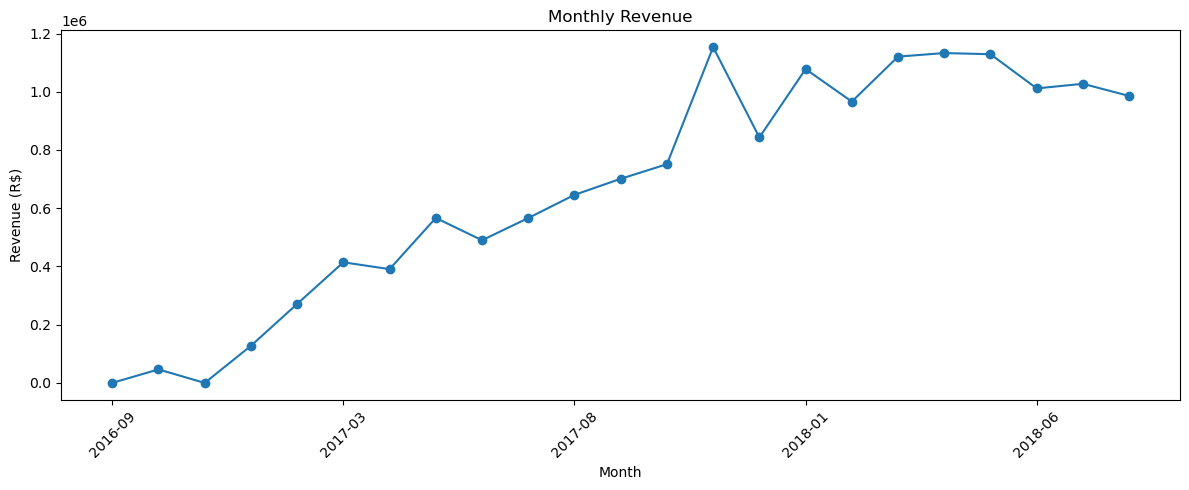

In [4]:
monthly = df.groupby('month')['revenue'].sum()

plt.figure(figsize=(12, 5))
monthly.plot(marker='o')
plt.title('Monthly Revenue')
plt.xlabel('Month')
plt.ylabel('Revenue (R$)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../images/monthly_revenue.png', bbox_inches='tight')
plt.show()

In [5]:
monthly = df.groupby('month')['revenue'].sum()

print('Sabse zyada revenue wala month:', monthly.idxmax(), '->', round(monthly.max(), 2))
print()
print(monthly.round(0).to_string())

Sabse zyada revenue wala month: 2017-11 -> 1153229.37

month
2016-09        143.0
2016-10      46491.0
2016-12         20.0
2017-01     127482.0
2017-02     271239.0
2017-03     414331.0
2017-04     390812.0
2017-05     566657.0
2017-06     490050.0
2017-07     566299.0
2017-08     645832.0
2017-09     701077.0
2017-10     751117.0
2017-11    1153229.0
2017-12     843078.0
2018-01    1077887.0
2018-02     966168.0
2018-03    1120598.0
2018-04    1132879.0
2018-05    1128775.0
2018-06    1011449.0
2018-07    1027287.0
2018-08     985492.0


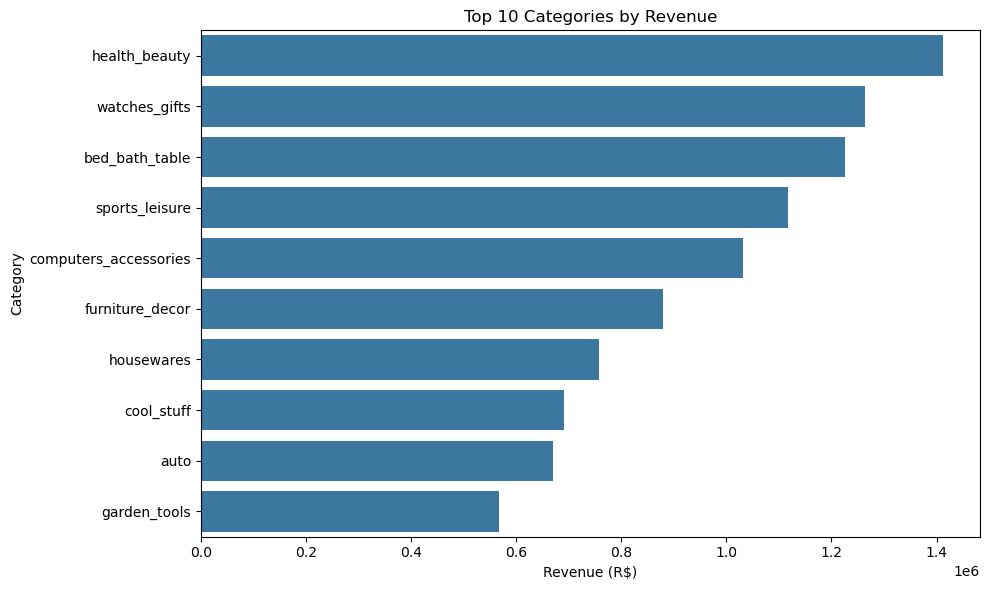

In [6]:
top_cat = df.groupby('category')['revenue'].sum().nlargest(10)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_cat.values, y=top_cat.index, color='#2a7ab0')
plt.title('Top 10 Categories by Revenue')
plt.xlabel('Revenue (R$)')
plt.ylabel('Category')
plt.tight_layout()
plt.savefig('../images/top_categories.png', bbox_inches='tight')
plt.show()

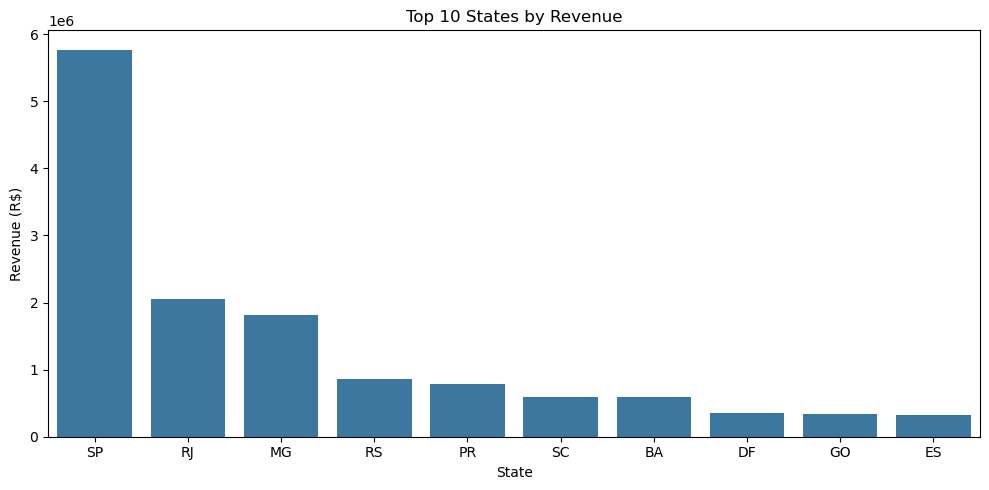

In [7]:
top_state = df.groupby('customer_state')['revenue'].sum().nlargest(10)

plt.figure(figsize=(10, 5))
sns.barplot(x=top_state.index, y=top_state.values, color='#2a7ab0')
plt.title('Top 10 States by Revenue')
plt.xlabel('State')
plt.ylabel('Revenue (R$)')
plt.tight_layout()
plt.savefig('../images/top_states.png', bbox_inches='tight')
plt.show()

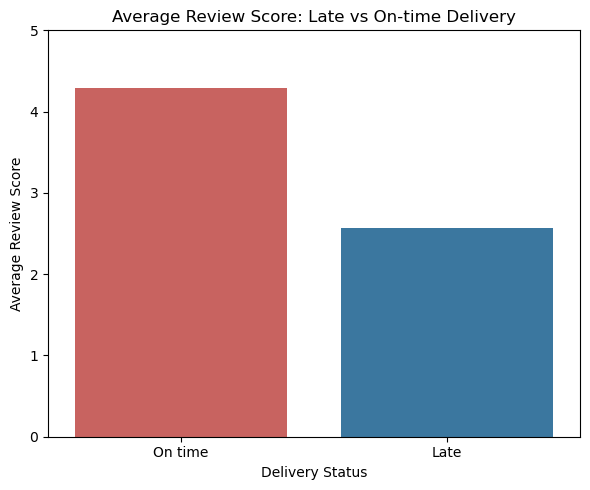

In [8]:
review_df = pd.read_sql("""
SELECT
    CASE WHEN o.order_delivered_customer_date > o.order_estimated_delivery_date
         THEN 'Late' ELSE 'On time' END AS delivery_status,
    ROUND(AVG(r.review_score), 2) AS avg_review
FROM orders o
JOIN order_reviews r ON o.order_id = r.order_id
WHERE o.order_delivered_customer_date IS NOT NULL
GROUP BY 1
""", engine)

plt.figure(figsize=(6, 5))
sns.barplot(data=review_df, x='delivery_status', y='avg_review',
            hue='delivery_status', palette=['#d9534f', '#2a7ab0'], legend=False)
plt.title('Average Review Score: Late vs On-time Delivery')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.tight_layout()
plt.savefig('../images/delivery_vs_review.png', bbox_inches='tight')
plt.show()

In [12]:
monthly = df.groupby('month')['revenue'].sum()
print('Month with the highest revenue:', monthly.idxmax(), '->', round(monthly.max(), 2))

Month with the highest revenue: 2017-11 -> 1153229.37


In [11]:
monthly = df.groupby('month')['revenue'].sum()

print('Month with the highest revenue:', monthly.idxmax())
print('Revenue in that month (R$):', round(monthly.max(), 2))
print()
print(monthly.round(0).to_string())

Month with the highest revenue: 2017-11
Revenue in that month (R$): 1153229.37

month
2016-09        143.0
2016-10      46491.0
2016-12         20.0
2017-01     127482.0
2017-02     271239.0
2017-03     414331.0
2017-04     390812.0
2017-05     566657.0
2017-06     490050.0
2017-07     566299.0
2017-08     645832.0
2017-09     701077.0
2017-10     751117.0
2017-11    1153229.0
2017-12     843078.0
2018-01    1077887.0
2018-02     966168.0
2018-03    1120598.0
2018-04    1132879.0
2018-05    1128775.0
2018-06    1011449.0
2018-07    1027287.0
2018-08     985492.0


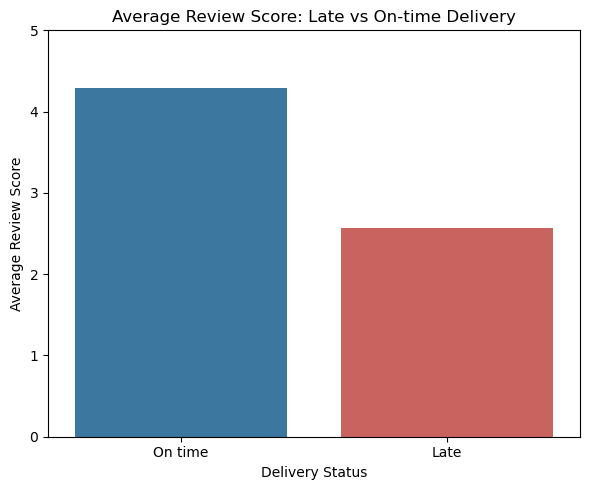

In [10]:
plt.figure(figsize=(6, 5))
sns.barplot(data=review_df, x='delivery_status', y='avg_review',
            order=['On time', 'Late'],
            hue='delivery_status',
            palette={'On time': '#2a7ab0', 'Late': '#d9534f'},
            legend=False)
plt.title('Average Review Score: Late vs On-time Delivery')
plt.xlabel('Delivery Status')
plt.ylabel('Average Review Score')
plt.ylim(0, 5)
plt.tight_layout()
plt.savefig('../images/delivery_vs_review.png', bbox_inches='tight')
plt.show()

# E-commerce Sales Analytics (Olist, Brazil)

**Goal:** Understand revenue drivers, top categories and states, and how delivery delays affect customer reviews.

**Tools:** MySQL, Python (Pandas, Matplotlib, Seaborn)

**Dataset:** Olist Brazilian E-commerce (~100K orders, 2016-2018)

---

## Key Insights

1. **Revenue:** Between 2016 and 2018, 96,477 delivered orders generated about **R\$ 15.4M** in revenue.

2. **Growth:** Monthly revenue grew steadily through 2017 and peaked in **November 2017 at about R\$ 1.15M** (likely driven by Black Friday). In 2018 it stabilised at around **R\$ 1.0M to R\$ 1.1M per month**.

3. **Geography:** São Paulo (SP) alone contributes about 37% of revenue. SP, RJ and MG together account for about 63%.

4. **Delivery:** About 8% of orders were delivered late. Late orders averaged a review score of 2.57, compared with 4.29 for on-time orders.

5. **Payments:** Credit cards account for about 78% of payment revenue.

6. **Categories:** health_beauty (~R\$ 1.4M), watches_gifts (~R\$ 1.26M) and bed_bath_table (~R\$ 1.23M) are the top 3 categories by revenue.

---

## Recommendations

1. **Reduce late deliveries.** Late orders score about 1.7 points lower in reviews (2.57 vs 4.29). Work with logistics partners, set more realistic delivery estimates, and prioritise the routes where delays are most common.

2. **Reduce dependence on São Paulo.** SP contributes 37% of revenue and the top 3 states contribute 63%. Grow sales in states like RS and PR through regional marketing and faster shipping options.

3. **Prepare early for peak season.** November 2017 was the highest revenue month, so stock up inventory, add delivery capacity and plan promotions before Black Friday. Delays during peak months can hurt reviews the most.

4. **Focus on top categories.** health\_beauty, watches\_gifts and bed\_bath\_table lead revenue. Invest in better inventory, bundles and promotions for these, while testing growth in mid-ranking categories like computers\_accessories and furniture\_decor.

5. **Promote credit card offers and EMI plans.** Since about 78% of revenue comes through cards, installment offers and card partnerships can increase order value and conversion.